# Lab Problem 7 : Exploring Kernel Methods and the Kernel Trick Using the XOR Dataset

Task 1: XOR Dataset Visualization

In [10]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

centers = [(1, 1), (-1, -1), (1, -1), (-1, 1)]
labels = [1, 1, -1, -1]

X = []
y = []

for center, label in zip(centers, labels):
    points = np.random.multivariate_normal(
        mean=center,
        cov=np.eye(2),
        size=25
    )

    X.append(points)
    y.extend([label] * 25)

X = np.vstack(X)
y = np.array(y)

print("Total samples:", len(X))
print("Features:", X.shape[1])
print("Class +1:", np.sum(y == 1))
print("Class -1:", np.sum(y == -1))

Total samples: 100
Features: 2
Class +1: 50
Class -1: 50


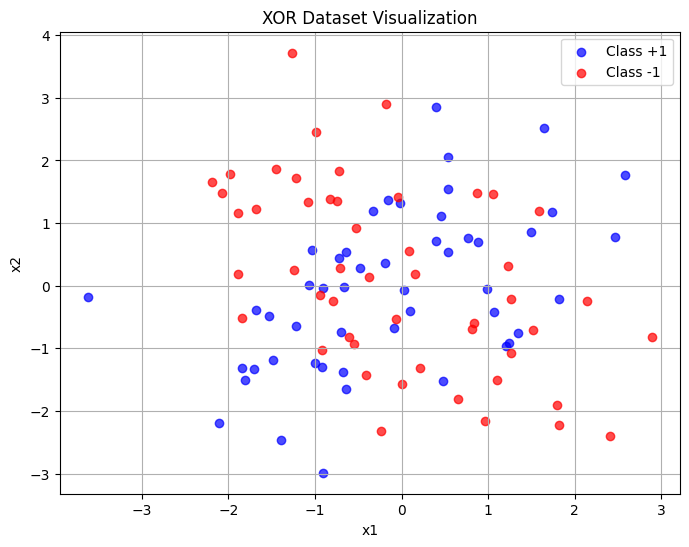

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    label="Class +1",
    alpha=0.7
)

plt.scatter(
    X[y == -1, 0],
    X[y == -1, 1],
    color="red",
    label="Class -1",
    alpha=0.7
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR Dataset Visualization")
plt.legend()
plt.grid(True)

plt.show()

Task 2: Implement Kernel Functions

In [12]:
def linear_kernel(X, Z):
    return X @ Z.T

In [13]:
def polynomial_kernel(X, Z):
    return (X @ Z.T) **2

In [14]:
def rbf_kernel(X, Z, gamma=0.5):
    X_sq = np.sum(X ** 2, axis=1).reshape(-1, 1)
    Z_sq = np.sum(Z ** 2, axis=1).reshape(1, -1)

    distances_sq = X_sq + Z_sq - 2 * (X @ Z.T)
    distances_sq = np.maximum(distances_sq, 0)

    return np.exp(-gamma * distances_sq)

In [15]:
K_linear = linear_kernel(X, X)
K_poly = polynomial_kernel(X, X)
K_rbf = rbf_kernel(X, X, gamma=0.5)

print("Linear Kernel Shape:", K_linear.shape)
print("Polynomial Kernel Shape:", K_poly.shape)
print("RBF Kernel Shape:", K_rbf.shape)

print("\nLinear Kernel (first 5x5):")
print(np.round(K_linear[:5, :5], 3))

print("\nPolynomial Kernel (first 5x5):")
print(np.round(K_poly[:5, :5], 3))

print("\nRBF Kernel (first 5x5):")
print(np.round(K_rbf[:5, :5], 3))

Linear Kernel Shape: (100, 100)
Polynomial Kernel Shape: (100, 100)
RBF Kernel Shape: (100, 100)

Linear Kernel (first 5x5):
[[2.983 4.64  1.806 5.383 2.123]
 [4.64  9.081 3.194 8.709 4.766]
 [1.806 3.194 1.173 3.329 1.588]
 [5.383 8.709 3.329 9.776 4.095]
 [2.123 4.766 1.588 4.095 2.661]]

Polynomial Kernel (first 5x5):
[[ 8.897 21.532  3.262 28.981  4.509]
 [21.532 82.457 10.203 75.847 22.715]
 [ 3.262 10.203  1.376 11.082  2.521]
 [28.981 75.847 11.082 95.573 16.767]
 [ 4.509 22.715  2.521 16.767  7.081]]

RBF Kernel (first 5x5):
[[1.    0.249 0.762 0.369 0.497]
 [0.249 1.    0.145 0.487 0.331]
 [0.762 0.145 1.    0.117 0.719]
 [0.369 0.487 0.117 1.    0.12 ]
 [0.497 0.331 0.719 0.12  1.   ]]


Task 3: Compute Kernel Matrices

In [16]:
X_8 = X[:8]

K_linear_8 = linear_kernel(X_8, X_8)
K_poly_8 = polynomial_kernel(X_8, X_8)
K_rbf_8 = rbf_kernel(X_8, X_8, gamma=0.5)

print("Linear Kernel Matrix:")
print(np.round(K_linear_8, 2))

print("\nPolynomial Kernel Matrix (Degree 2):")
print(np.round(K_poly_8, 2))

print("\nRBF Kernel Matrix (gamma = 0.5):")
print(np.round(K_rbf_8, 2))

Linear Kernel Matrix:
[[ 2.98  4.64  1.81  5.38  2.12  1.26  1.07 -0.71]
 [ 4.64  9.08  3.19  8.71  4.77  2.23 -0.26 -0.09]
 [ 1.81  3.19  1.17  3.33  1.59  0.82  0.25 -0.22]
 [ 5.38  8.71  3.33  9.78  4.09  2.33  1.59 -1.1 ]
 [ 2.12  4.77  1.59  4.09  2.66  1.11 -0.75  0.29]
 [ 1.26  2.23  0.82  2.33  1.11  0.57  0.18 -0.16]
 [ 1.07 -0.26  0.25  1.59 -0.75  0.18  2.38 -1.3 ]
 [-0.71 -0.09 -0.22 -1.1   0.29 -0.16 -1.3   0.72]]

Polynomial Kernel Matrix (Degree 2):
[[8.900e+00 2.153e+01 3.260e+00 2.898e+01 4.510e+00 1.600e+00 1.150e+00
  5.000e-01]
 [2.153e+01 8.246e+01 1.020e+01 7.585e+01 2.272e+01 4.980e+00 7.000e-02
  1.000e-02]
 [3.260e+00 1.020e+01 1.380e+00 1.108e+01 2.520e+00 6.700e-01 6.000e-02
  5.000e-02]
 [2.898e+01 7.585e+01 1.108e+01 9.557e+01 1.677e+01 5.420e+00 2.530e+00
  1.200e+00]
 [4.510e+00 2.272e+01 2.520e+00 1.677e+01 7.080e+00 1.230e+00 5.600e-01
  8.000e-02]
 [1.600e+00 4.980e+00 6.700e-01 5.420e+00 1.230e+00 3.300e-01 3.000e-02
  2.000e-02]
 [1.150e+00 7.000e-02

Task 4: Kernel Matrix Visualization

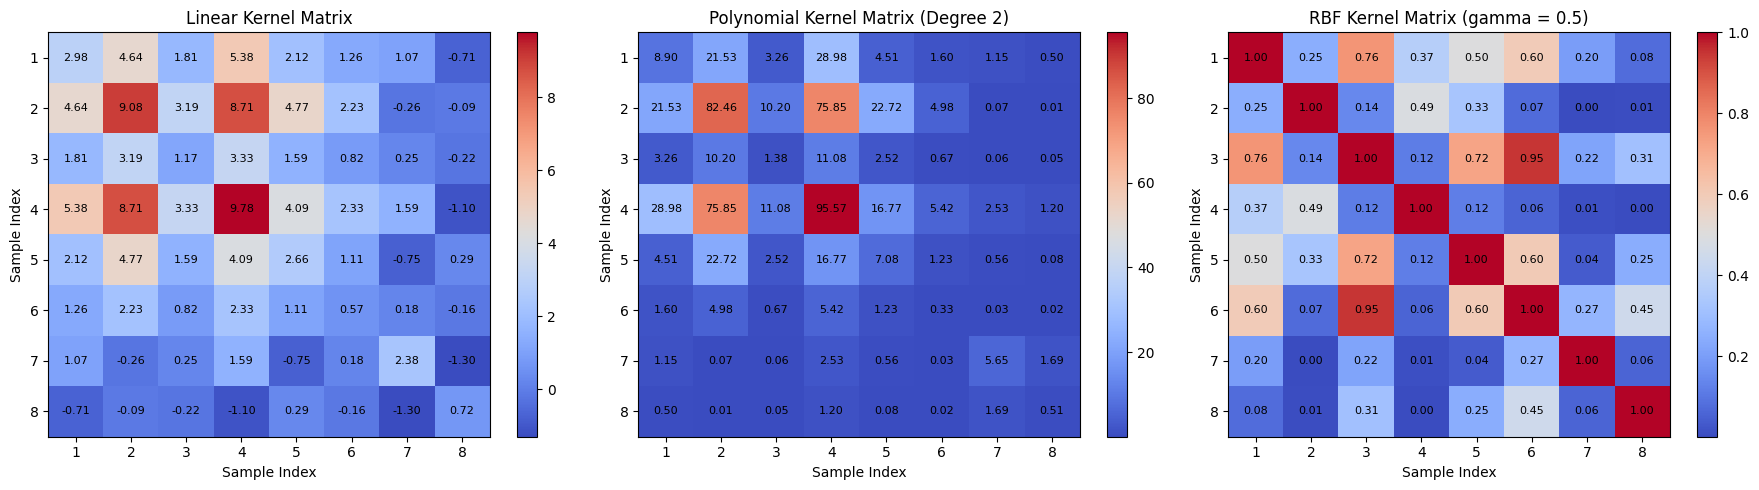

In [17]:
matrices = [
    K_linear_8,
    K_poly_8,
    K_rbf_8
]

titles = [
    "Linear Kernel Matrix",
    "Polynomial Kernel Matrix (Degree 2)",
    "RBF Kernel Matrix (gamma = 0.5)"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

indices = np.arange(1, 9)

for ax, matrix, title in zip(axes, matrices, titles):

    im = ax.imshow(matrix, cmap="coolwarm", aspect="auto")

    ax.set_title(title)
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Sample Index")

    ax.set_xticks(np.arange(8))
    ax.set_yticks(np.arange(8))
    ax.set_xticklabels(indices)
    ax.set_yticklabels(indices)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i,
                f"{matrix[i, j]:.2f}",
                ha="center",
                va="center",
                color="black",
                fontsize=8
            )

    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

Task 5: Explicit Feature Mapping

Original dataset shape: (100, 2)
Transformed dataset shape: (100, 3)


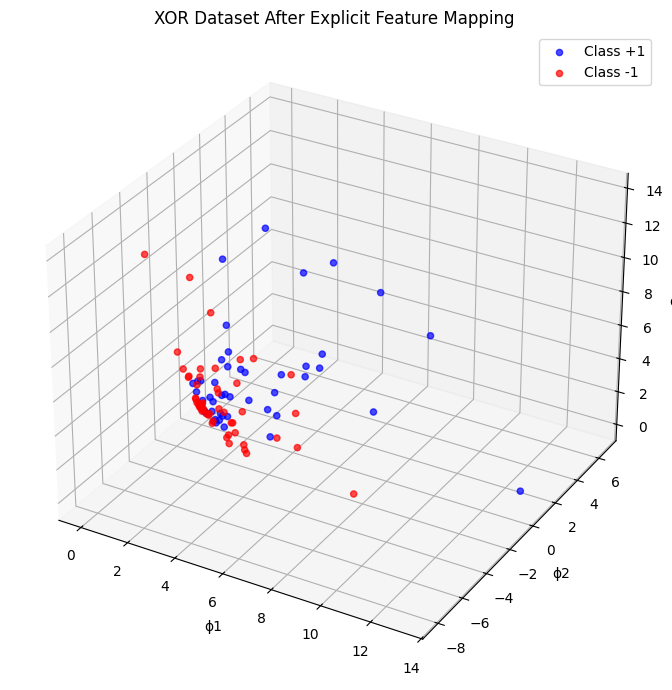

In [18]:
X_mapped = np.column_stack((
    X[:, 0] ** 2,
    np.sqrt(2) * X[:, 0] * X[:, 1],
    X[:, 1] ** 2
))

print("Original dataset shape:", X.shape)
print("Transformed dataset shape:", X_mapped.shape)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_mapped[y == 1, 0],
    X_mapped[y == 1, 1],
    X_mapped[y == 1, 2],
    color="blue",
    label="Class +1",
    alpha=0.7
)

ax.scatter(
    X_mapped[y == -1, 0],
    X_mapped[y == -1, 1],
    X_mapped[y == -1, 2],
    color="red",
    label="Class -1",
    alpha=0.7
)

ax.set_xlabel("ϕ1")
ax.set_ylabel("ϕ2")
ax.set_zlabel("ϕ3")
ax.set_title("XOR Dataset After Explicit Feature Mapping")

ax.legend()
plt.tight_layout()
plt.show()